# 04 · 结构导出与论文结果：衔接科学评估
**DP-EVA 实验课堂 · 约 5 分钟**

前面解决“选哪些结构”，这里把输出交给真实工作流，再回看论文中经过训练与验证的结果。

本节可独立执行：会按显式默认参数生成一次新导出。所有文件写入 `work/`，不启动训练、DFT 或 Slurm。


In [1]:
%matplotlib inline
from pathlib import Path
import os, sys
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
candidates = [Path.cwd(), Path.cwd() / 'examples/tutorials/paper_case']
TUTORIAL = next((p.resolve() for p in candidates if (p / 'tutorial_support.py').is_file()), None)
if TUTORIAL is None:
    raise RuntimeError('请从仓库根目录或 paper_case 目录启动 Jupyter。')
sys.path.insert(0, str(TUTORIAL))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
import tutorial_support as t
bundle = t.load_bundle()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .15})
print('DP-EVA 源码: 当前仓库 src/dpeva')
print('模型: DPA-3.1-3M / OC22 | 当前使用论文预计算数据，无需 GPU')


DP-EVA 源码: 当前仓库 src/dpeva
模型: DPA-3.1-3M / OC22 | 当前使用论文预计算数据，无需 GPU


In [2]:
import json
parameters = t.paper_parameters()
selection = t.sample_live(**parameters)
display(t.compare_paper_selection(selection))
output = t.export_selection(selection['selected_pool_indices'])
(output / 'parameters.json').write_text(json.dumps(dict(parameters, resolved_thresholds=t.uq_thresholds(parameters['low'], parameters['high'])), indent=2) + '\n')
# 当前 workflow 配置路径相对其自身所在目录解析。
analysis_config = {'mode':'dataset', 'dataset_dir':'label_input', 'output_dir':'analysis'}
(output / 'analysis.json').write_text(json.dumps(analysis_config, indent=2) + '\n')
print('导出目录:', output.relative_to(TUTORIAL))
print('结构数量:', len(selection['selected_pool_indices']))
print('DeepMD 输入示例:', sorted((output / 'label_input').iterdir())[0].name)
print('在完整 DP-EVA 环境中可运行：')
print('从教学目录运行：dpeva analysis', (output / 'analysis.json').relative_to(TUTORIAL))


,论文名单对照（选数后）
本次新增,833
历史新增,843
名单交集,737
仅本次,96
仅历史,106
名单完全一致,False


导出目录: work/selection-7ae3hr7h
结构数量: 833
DeepMD 输入示例: frame_0000
在完整 DP-EVA 环境中可运行：
从教学目录运行：dpeva analysis work/selection-7ae3hr7h/analysis.json


## 工作流交接图

`feature → 初始选数 → train → infer → UQ + collect → label → 加入训练集 → 再训练与评估`

- 本次 `label_input/` 是无标签的 DeepMD npy 目录；`selected.extxyz` 可供结构查看；`selected.csv` 是交接索引。
- ABACUS 标注需要配置赝势、轨道和计算环境。参考 [配置说明](configs/README.md)，可通过 `--stage prepare` 先检查生成的输入。
- 已有 DFT 标签在教学中相当于隐藏的答案。现实中新生成的结构需要真正计算标签。
- 对新增数据训练后，再通过推理和误差评估检验模型是否改进。

课后先运行仓库 [四阶段 quickstart](../../recipes/quickstart/README.md)。它使用 **1 帧训练 + 5 帧候选、30 步训练**，用于验证接口衔接。


## 论文一轮迭代：从 3,000 到 3,843 帧
论文 Table 2 展示将选点加入训练集后，各策略的模型误差。每种策略在各自采样后剩余的数据上评估；这是原实验的评估口径。

本节读取并重绘论文报告值，将前面的选数过程与原实验的训练效果联系起来。现场改变参数后的选择需要后续训练，才能得到对应的精度结果。


,feature,strategy,new_frames,train_frames,energy_rmse_mev_atom,force_rmse_ev_A
4,SOAP,DIRECT,1000,4000,13.02,0.3685
5,SOAP,Joint-DIRECT,1101,4101,18.83,0.7050
6,SOAP,UQ + DIRECT,1000,4000,7.77,0.1294
7,SOAP,UQ + Joint-DIRECT,748,3748,10.00,0.1128
8,DPA3,DIRECT,1000,4000,6.00,0.1005
9,DPA3,Joint-DIRECT,1261,4261,6.06,0.0994
10,DPA3,UQ + DIRECT,1000,4000,6.48,0.0996
11,DPA3,UQ + Joint-DIRECT,843,3843,5.87,0.1002


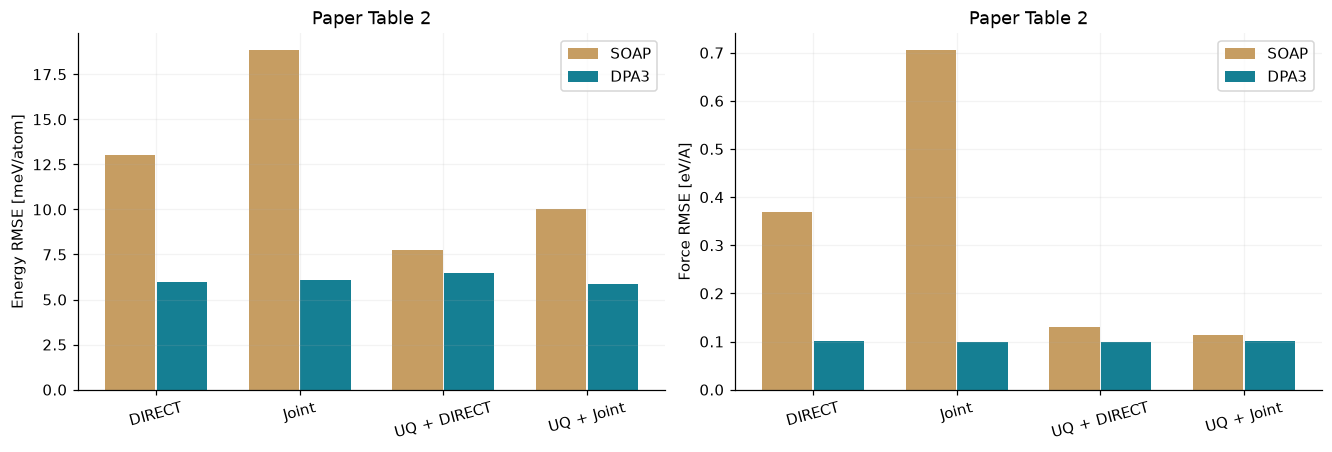

In [3]:
metrics = pd.read_csv(TUTORIAL / 'data/paper_metrics.csv')
iteration = metrics.query("stage == 'iteration'")
display(iteration[['feature','strategy','new_frames','train_frames','energy_rmse_mev_atom','force_rmse_ev_A']])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for feature, color in [('SOAP','#c69d62'), ('DPA3','#157f93')]:
    group = iteration[iteration.feature == feature]
    x = np.arange(len(group)) + (-.18 if feature == 'SOAP' else .18)
    axes[0].bar(x, group.energy_rmse_mev_atom, width=.35, label=feature, color=color)
    axes[1].bar(x, group.force_rmse_ev_A, width=.35, label=feature, color=color)
labels = ['DIRECT','Joint','UQ + DIRECT','UQ + Joint']
for ax in axes:
    ax.set_xticks(range(4), labels, rotation=15)
    ax.legend()
axes[0].set(ylabel='Energy RMSE [meV/atom]', title='Paper Table 2')
axes[1].set(ylabel='Force RMSE [eV/A]', title='Paper Table 2')
plt.show()


**图 8｜论文第一轮迭代的能量与力误差。** 比较 SOAP 与 DPA3 特征下的四种选数策略。来源：论文 Table 2，由本地指标表重绘；各方案的评估集合口径见正文。

## 回到研究问题
**论文表明，代表性采样与模型不确定度结合，可以用约 12.5% 的数据取得接近全量参考的能量精度。** DPA3 + UQ + joint-DIRECT 最终使用 3,843 帧，能量 RMSE 约为 **5.9 meV/atom**，全量参考约为 **5.6 meV/atom**；力 RMSE 分别约为 **0.100 与 0.082 eV/Å**，力的差距仍需单独关注。表格保留论文原始报告位数，正文使用便于比较的有效数字。

教程现场复算了覆盖、UQ 分类和联合采样，并生成可交接的结构目录；这些结果支持选数方法的主要趋势。精度结果来自论文训练实验，两部分共同说明“代表性 + 模型信息 + 实际评估”的研究闭环。

论文进一步在 Fe₅C₂ 表面反应与重构上验证模型应用效果；这部分作为应用延伸阅读，方法与结果见 [论文](https://doi.org/10.1093/ce/zkag029)。


In [4]:
selected = metrics.query("stage == 'iteration' and feature == 'DPA3' and strategy == 'UQ + Joint-DIRECT'").iloc[0]
print(f'论文选中总训练帧数：{int(selected.train_frames)} / 30656 = {selected.train_frames / 30656:.2%}')
print('历史新增结构名单：data/paper_selected.csv，共', len(bundle['paper_selected']), '帧')
print('本次教学导出：', len(selection['selected_pool_indices']), '帧；当前未进行再训练')


论文选中总训练帧数：3843 / 30656 = 12.54%
历史新增结构名单：data/paper_selected.csv，共 843 帧
本次教学导出： 833 帧；当前未进行再训练


## 从验证误差走向研究任务
论文进一步询问：用少量数据得到的模型，能否支持 Fe₅C₂ 表面的反应与结构稳定性研究？

**反应测试覆盖 22 项量：2 项吸附能，以及 10 个基元反应的反应能和势垒。** 下表摘录论文 Table 3，均为相对 DFT 的误差，单位 eV：

| 模型 | MAE | RMSE | 最大绝对误差 |
|---|---:|---:|---:|
| DPA3 全量微调 | 0.069 | 0.095 | 0.289 |
| DPA3 子集微调（3,843 帧） | 0.077 | 0.091 | 0.156 |

子集模型的 RMSE 接近全量，MAE 略高，最大误差更小，支持本测试中的整体可比表现。这里的 eV 是吸附能、反应能和势垒的误差单位，与前面逐原子能量误差的 meV/atom 对应不同物理量。数据源为论文 Table 3；逐项数据见 Table S1，本节用于解读原实验。

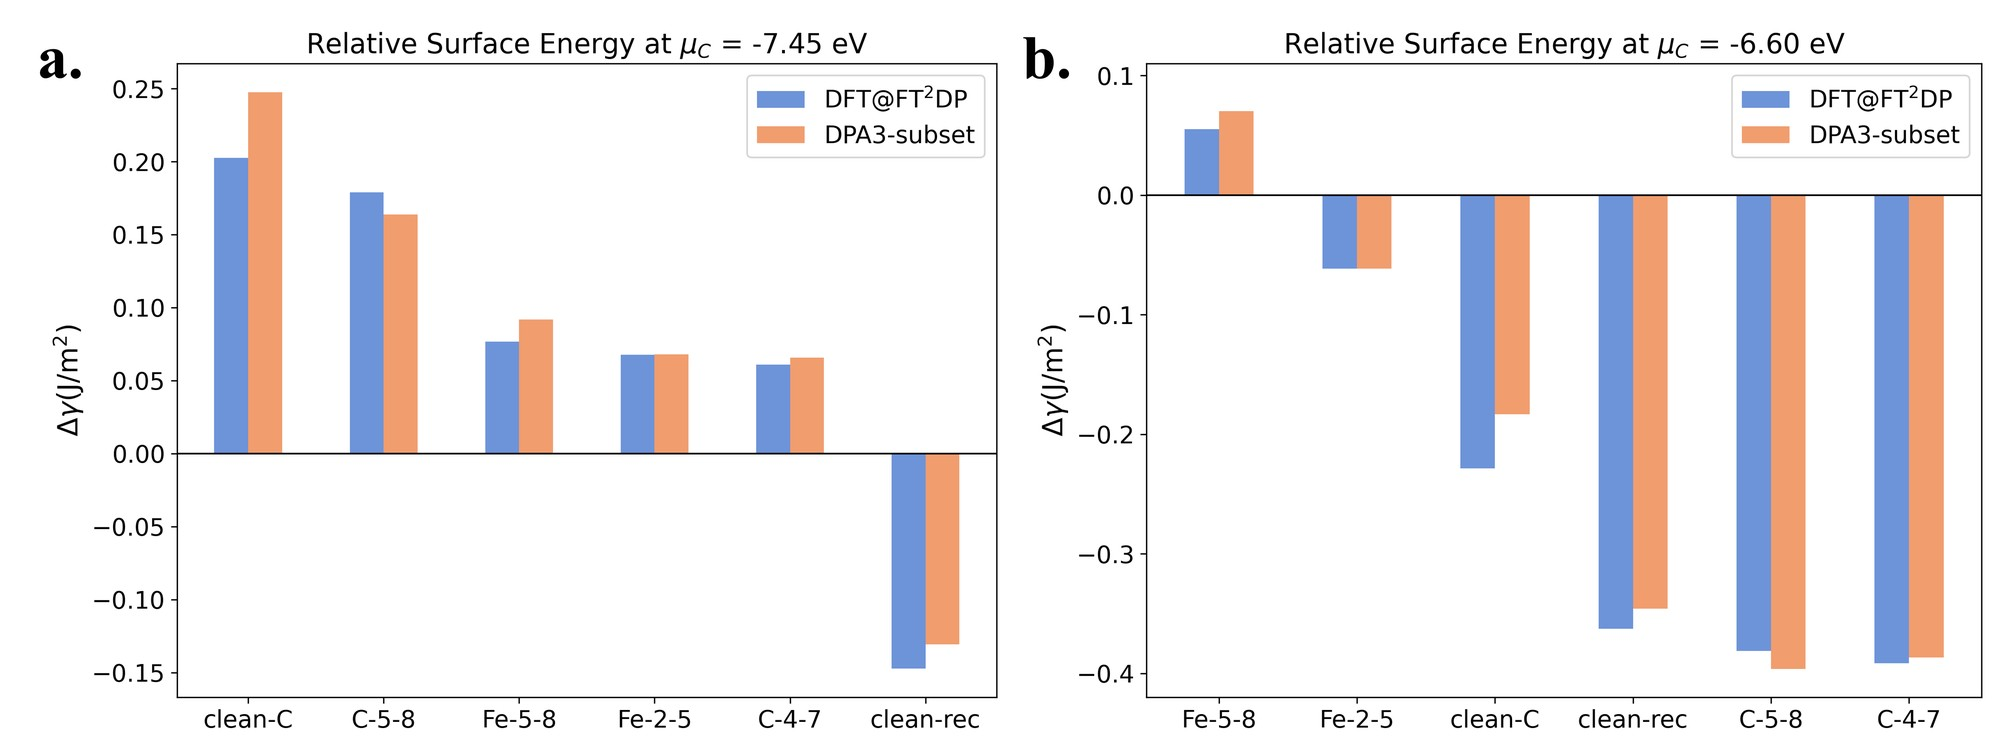

**论文图 5｜不同碳化学势下的重构表面稳定性。** 左右分别对应 $\mu_C=-7.45$ 与 $-6.60$ eV；纵轴为相对表面能，单位 J/m²。蓝色为对 FT²DP 工作所获结构进行 DFT 单点计算的参照，橙色为 DPA3 子集模型结果。先看低能结构的分布与排序，再看数值偏差。来源：Liu 等，DP-EVA，Figure 5；作者提供的 JPG 版本，CC BY-NC 4.0，未改绘；计算定义见论文式 (7)–(8)。

**讨论**：反应能接近，是否足以支持完整反应网络研究？还应检查关键势垒、竞争路径与相关构型的覆盖。迁移到自己的 FeCHO / FT²DP-v2 工作时，可把这些问题转成预先固定的应用测试集。

课堂用 1 分钟读表和看图即可；反应路径、表面自由能及结构优化方法留作课后阅读：[DP-EVA](https://doi.org/10.1093/ce/zkag029)、[FT²DP](https://doi.org/10.20517/jmi.2024.105)。本节未重新计算反应路径或表面自由能。


## 课后路线与 DPA4 延伸
1. 更改 UQ 区间和聚类数，导出两套选择名单，检查重复与新增区域。
2. 在完整计算环境中跑通 quickstart，再将自己的数据接入 recipes。
3. 比较新的采样方法时，提前固定共同留出集，并保证模型、训练预算与标注口径可比。
4. 迁移到 DPA4-Air-ZBL-MatPES 时，更换基座并重新生成特征和委员会预测；保留 ZBL 设置，核对能量参考和训练方式。不能沿用 DPA3 的 UQ 或论文精度数值。

**带走的工作产物**：结构文件、来源索引、显式选择参数，以及可接入下一阶段的数据目录。

方法原文、中文推介与当前实现的对应关系见 [参考资料](REFERENCES.md)。建议先读 DP-EVA Figure 1 和 Methods，再按研究需求读 DIRECT 与 FT²DP。
